<small>Dataset: Salary Data.csv</small>

# Q12. Salary Linear Regression

Learn the relationship between experience and salary, then predict a salary.


## Question from Classroom

Salary Estimation Using Linear Regression 
Problem statement: Build a model to estimate employee salary based on years of 
experience. 
Tasks to be performed: 
1. Load or create a suitable salary dataset. 
2. Visualize the relationship between experience and salary. 
3. Split the data into training and testing sets. 
4. Train a Linear Regression model. 
5. Display the regression equation and fitted regression line. 
6. Predict salary for a user-entered number of years of experience. 
7. Evaluate the model using R², RMSE and MAE.


## Understand before coding

X = experience, y = salary. Split -> fit -> predict -> evaluate. This is the easiest regression notebook to learn first.


Run the code cells from top to bottom with **Shift + Enter**. If an import is missing, run the following installation line once in a new cell, then restart the kernel. The line below is a comment until you remove `#`.


**Optional package setup (run once in a new Jupyter cell if needed):**

```python
%pip install pandas numpy matplotlib scikit-learn openpyxl
```


**Code layout:** 7 listed tasks → 7 code blocks. Run them in order. Imports and helper definitions are included in the relevant task. Where the PDF repeats a task number, these blocks follow its listed order. Learned preprocessing is fitted only after splitting.


## Task 1. Load or create a suitable salary dataset.

This block implements the task above. Variables from earlier blocks are reused.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
df=pd.read_csv("data/Salary Data.csv").dropna()
X=df[["YearsExperience"]]
y=df["Salary"]
print(df.head())


   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0


## Task 2. Visualize the relationship between experience and salary.

This block implements the task above. Variables from earlier blocks are reused.


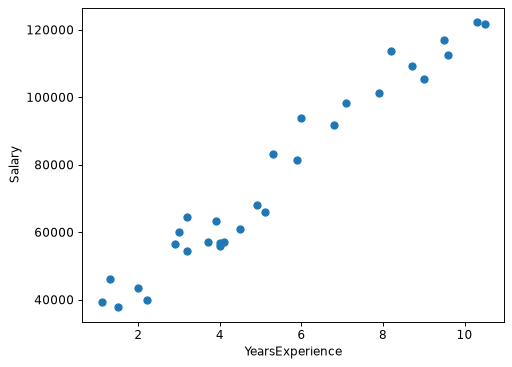

In [2]:
plt.scatter(df["YearsExperience"],y)
plt.xlabel("YearsExperience");plt.ylabel("Salary");plt.show()


## Task 3. Split the data into training and testing sets.

This block implements the task above. Variables from earlier blocks are reused.


In [3]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)


## Task 4. Train a Linear Regression model.

This block implements the task above. Variables from earlier blocks are reused.


In [4]:
model=LinearRegression()
model.fit(X_train,y_train)


## Task 5. Display the regression equation and fitted regression line.

This block implements the task above. Variables from earlier blocks are reused.


Salary = 25321.58 + 9423.82 * YearsExperience


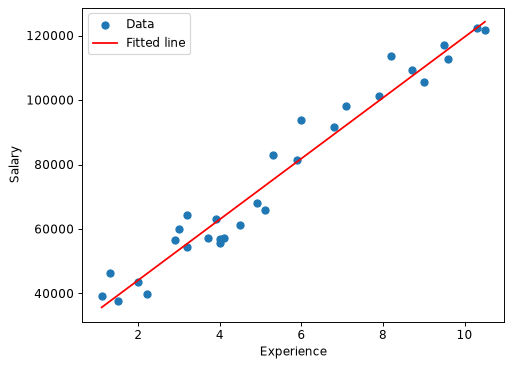

In [5]:
print("Salary =",round(model.intercept_,2),"+",round(model.coef_[0],2),"* YearsExperience")
ordered=X.sort_values("YearsExperience")
plt.scatter(df["YearsExperience"],y,label="Data")
plt.plot(ordered["YearsExperience"],model.predict(ordered),color="red",label="Fitted line")
plt.xlabel("Experience");plt.ylabel("Salary");plt.legend();plt.show()


## Task 6. Predict salary for a user-entered number of years of experience.

This block implements the task above. Variables from earlier blocks are reused.


In [6]:
years=float(input("Years of experience [5]: ") or "5")
new_record=pd.DataFrame({"YearsExperience":[years]})
print("Predicted salary:",round(model.predict(new_record)[0],2))


Years of experience [5]: 
Predicted salary: 72440.66


## Task 7. Evaluate the model using R², RMSE and MAE.

This block implements the task above. Variables from earlier blocks are reused.


In [7]:
prediction=model.predict(X_test)

print("R2:",round(r2_score(y_test,prediction),4))
print("RMSE:",round(np.sqrt(mean_squared_error(y_test,prediction)),2))
print("MAE:",round(mean_absolute_error(y_test,prediction),2))
print(pd.DataFrame({"Actual":np.asarray(y_test),"Predicted":prediction}).head(10))


R2: 0.9024
RMSE: 7059.04
MAE: 6286.45
     Actual      Predicted
0  112635.0  115790.210113
1   67938.0   71498.278095
2  113812.0  102596.868661
3   83088.0   75267.804224
4   64445.0   55477.792045
5   57189.0   60189.699707


## Viva preparation guide



**1. What are X and y?**

X contains the predictor columns; y contains the target we want to predict. X is a 2D table and y is a 1D series.

**2. Why split training and testing data?**

Fit using the training examples. Evaluate on separate examples to estimate how well the model generalizes.

**3. What do fit() and predict() mean?**

fit() learns parameters from training examples. predict() applies the learned model to new feature rows.

**4. Why random_state=42?**

It makes random splits or model choices reproducible. The number 42 has no special mathematical meaning.

**5. What is data leakage?**

Information unavailable for a real prediction accidentally influences training. Examples: including the answer in X or fitting a scaler on test data. Fit learned preprocessing only on training data.

**6. What is overfitting?**

The model learns training-specific details/noise and does worse on unseen data. Control complexity and use validation or cross-validation.

**7. What is a hyperparameter?**

A setting chosen outside model fitting, such as max_depth, K or the number of trees. Choose it using training validation, not by repeatedly optimizing the final test result.

**8. How do I fix FileNotFoundError or KeyError?**

Open Jupyter in the praceice folder, keep data/ beside this notebook, and print df.columns.tolist() to check exact column names. Do not change X and y row counts separately.

**9. What is linear regression?**

It fits y_hat = b0 + b1*x1 + ... + bp*xp, normally by minimizing the sum of squared training residuals.

**10. What are intercept and coefficients?**

The intercept is the predicted value when encoded inputs are zero. A coefficient describes the change in prediction per unit of that feature, holding the others fixed; association does not prove causation.

**11. Define MAE and RMSE.**

MAE=mean(abs(y-y_hat)). RMSE=sqrt(mean((y-y_hat)^2)). Both use the target units; lower is better. RMSE penalizes large errors more strongly.

**12. What is R2?**

R2=1-SSE/SST. A perfect prediction scores 1. A negative score means worse squared error than predicting the test target mean. It is not accuracy or a percentage of correct records.

**13. How do I interpret actual vs predicted?**

Points near the diagonal indicate small errors. Systematic curves or large scatter suggest model limitations. Do not invent a good score when the dataset has weak signal.

**14. What is the equation here?**

Salary_hat = intercept + coefficient * YearsExperience. The notebook prints the learned intercept and slope.

**15. Why X=df[[...]] but y=df[...]?**

Double brackets produce a table with one feature column. A scikit-learn feature matrix must be 2D; y is a 1D target series.

**16. What does coef_[0] mean?**

The estimated salary change for one more year of experience in this simple fitted model.

**17. Does a salary estimate guarantee the actual salary?**

No. The model uses one predictor and a small dataset; real salaries depend on many factors. Avoid unsupported extrapolation beyond the training experience range.

**18. What is the computational idea?**

Choose the intercept and slope that minimize squared errors. This is supervised regression, not classification.


### Task-to-code map

- **Block 1:** Load or create a suitable salary dataset.
- **Block 2:** Visualize the relationship between experience and salary.
- **Block 3:** Split the data into training and testing sets.
- **Block 4:** Train a Linear Regression model.
- **Block 5:** Display the regression equation and fitted regression line.
- **Block 6:** Predict salary for a user-entered number of years of experience.
- **Block 7:** Evaluate the model using R², RMSE and MAE.
